# 39 智能优化算法

> **模块**：优化 ｜ **数据**：`../data/textbook/12.D 飞机侦察地理坐标数据.txt` ｜ **依赖**：numpy、pandas、matplotlib

## 1. 问题背景

模拟退火与遗传算法不依赖梯度，适合组合优化与多峰问题。前者以概率接受劣解跳出局部最优，后者通过选择、交叉、变异迭代种群。

## 2. 学习目标

- 理解退火温度与 Metropolis 接受准则
- 掌握遗传算法的编码、选择、交叉与变异
- 能调参并观察收敛过程

## 3. 环境与数据

- 依赖：numpy、pandas、matplotlib
- 数据：`../data/textbook/12.D 飞机侦察地理坐标数据.txt`

## 4. 方法与实现

### 4.1 模拟退火算法

- 优化函数(要使之最小)为: $f:x\rightarrow R^+$  
- 给定初始温度$T_0$和初始解$x(0)$, 并由$x_0$生成下一个解$x'\in N[x(0)]$,即$x_0$的邻域  
- 这个解是否被接受,依赖于以下概率: $$P(x(k)\rightarrow x')=\left\{\begin{array}{l}1,\qquad f(x')<f(x(k))\\e^{-\frac{f(x')-f(x(k))}{T_i}},\qquad otherwise.\\\end{array}\right.$$
- 这是一个马尔可夫过程

蒙特卡罗算法得到的路径长度: 222200.52746267183
[  0  86  65  84  41  85  23  79  27  55  57  76  87  69  29  58  10  12
  16   3  50  28  83  62  82  20  93  44  74   8  71  25  92  63  54  31
  61   5   1  19  68  60  66  91  43  40  89  81  47  99  72  14  80  26
  64  17  70  15  34  21  88  22  98  48  96  94 100  59  30  51  39  52
  90  33  97  56   4   9   7  13  42  45   6  67  73  46  32  49  36  75
  95  77  11  24  35  53  37  38   2  78  18 101]
模拟退火算法得到的路径长度: 43735.66603479423, 花费时间: 43.73566603479423
[  0  34  76   3 100  92  77  19  17  52  80  15  96  88  70  46  29  53
  94  16  98  62  73  91  14  65  54  35  12  18   4  51  37  71  99  60
  58   9  26  95  13  11   7  41  87  45  89  90  22  42  79  81  21  67
  93  20  27  85  40  56  30  10  97  59  43  47  69  25  50   8  82  23
   6  48  39  57  75  72  55  36  84  32  33   2  49  83  86  24  44  28
  31  78  68  66  38  64   1  63  74   5  61 101]


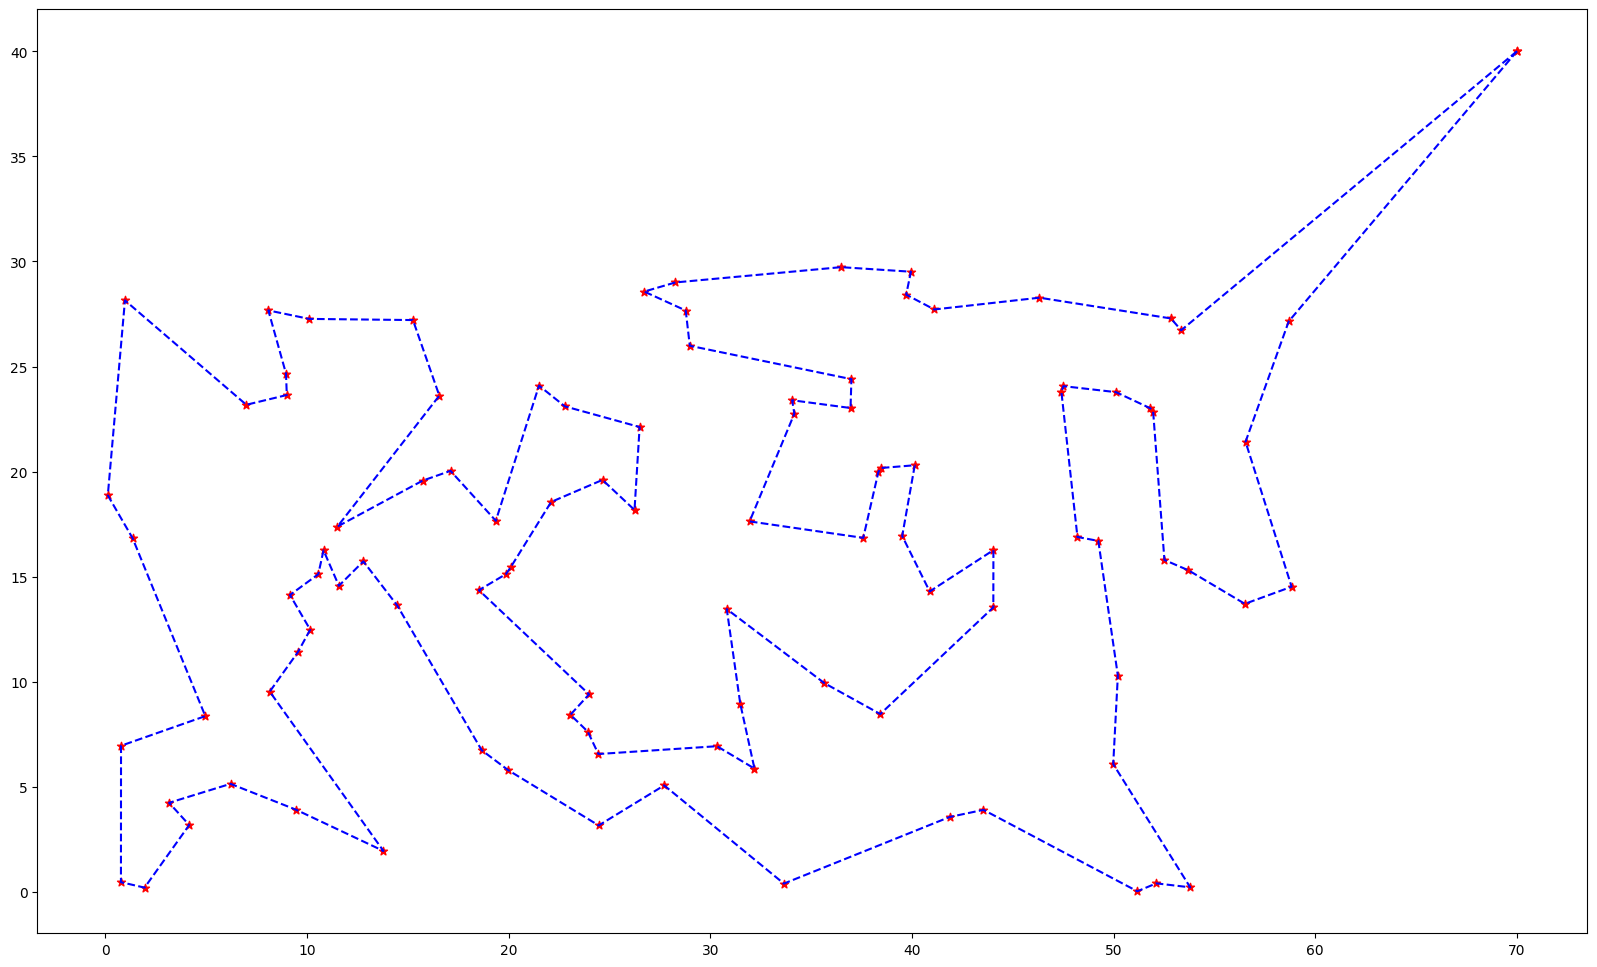

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- 数据读入、reshape ----------
data = np.loadtxt('../data/textbook/12.D 飞机侦察地理坐标数据.txt')
data = data.reshape((data.shape[0] * 4, 2))
data = np.insert(data, 0, values=[[70, 40]], axis=0)
data = np.insert(data, data.shape[0], values=[[70, 40]], axis=0)

# 地球半径
R = 6370

# ---------- 计算间距 ----------
d = np.zeros((data.shape[0], data.shape[0]), dtype=float)          # ← 修改
tempdata = data / 180 * np.pi
for i in range(len(d)):
    for j in range(i + 1, len(d)):
        d[i][j] = R * np.arccos(
            np.cos(tempdata[i][0] - tempdata[j][0]) * np.cos(tempdata[i][1]) * np.cos(tempdata[j][1])
            + np.sin(tempdata[i][1]) * np.sin(tempdata[j][1])
        )
d = d + d.T

# ---------- 蒙特卡洛求初始解 ----------
np.random.seed(0)
length = np.inf
for times in range(1000):
    temppath = np.array([0], dtype=int)                             # ← 修改
    temppath = np.insert(temppath, 1,
                         values=np.random.permutation([i + 1 for i in range(100)]),
                         axis=0)
    temppath = np.insert(temppath, temppath.shape[0], values=[101], axis=0)
    templen = 0
    for i in range(len(temppath) - 1):
        templen += d[temppath[i]][temppath[i + 1]]
    if templen < length:
        length = templen
        path = temppath
print('蒙特卡罗算法得到的路径长度: {}'.format(length), path, sep='\n')

# ---------- 模拟退火 ----------
alpha = 0.999
e = 1e-30
T = 1
for times in range(1000000):
    u, v = np.random.randint(low=1, high=101, size=(2))
    temppath = path.copy()
    temppath[u:v + 1] = path[v:u - 1:-1]
    df = (d[path[u - 1]][path[v]] + d[path[u]][path[v + 1]]
          - d[path[u - 1]][path[u]] - d[path[v]][path[v + 1]])
    if df < 0 or np.exp(-df / T) >= np.random.rand():
        path = temppath
        length += df
    T = T * alpha
    if T < e:
        break

length = 0
for i in range(len(path) - 1):
    length += d[path[i]][path[i + 1]]
print('模拟退火算法得到的路径长度: {}, 花费时间: {}'.format(length, length / 1000), path, sep='\n')

# ---------- 绘图 ----------
plt.figure(figsize=(20, 12))
divide = 1
coordinate_path = np.array([[data[i][0], data[i][1]] for i in path])
plt.scatter(coordinate_path[::divide, 0], coordinate_path[::divide, 1],
            marker='*', color='red')
plt.plot(coordinate_path[::divide, 0], coordinate_path[::divide, 1], 'b--')
plt.show()

### 4.2 遗传算法

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 数据读入, reshape
data = np.loadtxt('../data/textbook/12.D 飞机侦察地理坐标数据.txt')
data = data.reshape((data.shape[0]*4, 2))
data = np.insert(data, 0, values=[[70, 40]], axis=0)
data = np.insert(data, data.shape[0], values=[[70, 40]], axis=0)

# 地球半径
R = 6370

# 计算间距 —— 修复: np.float 已弃用, 用 float
d = np.zeros((data.shape[0], data.shape[0]), dtype=float)
tempdata = np.deg2rad(data)          # 等价于 data/180*np.pi, 更清晰

for i in range(len(d)):
    for j in range(i+1, len(d)):
        cos_val = (np.cos(tempdata[i][0] - tempdata[j][0])
                   * np.cos(tempdata[i][1]) * np.cos(tempdata[j][1])
                   + np.sin(tempdata[i][1]) * np.sin(tempdata[j][1]))
        # 用 clip 避免浮点误差导致 arccos 越界 (常见坑)
        d[i][j] = R * np.arccos(np.clip(cos_val, -1.0, 1.0))

d = d + d.T

In [5]:
np.random.seed(0)
# w为种群个数
w = 50
# g为进化的代数
g = 100

J = []
for k in range(w):
    # 生成初始解
    
    c1 = np.array([0, 101])
    c1 = np.insert(c1, 1, values=1 + np.random.permutation([i+1 for i in range(100)]), axis=0)
    for t in range(len(c1)):
        flag = 0
        for m in range(1, len(c1)-2):
            for n in range(m+2, len(c1)-1):
                if d[c1[m]][c1[n]] + d[c1[m+1]][c1[n+1]] < d[c1[m]][c1[m+1]] + d[c1[n]][c1[n+1]]:
                    c1[m:n+1] = c1[n:m-1:-1]
                    flag = 1
        if flag == 0:
            break
    J.append(c1)

np.savetxt('遗传算法初步结果.txt', J, fmt='%d')

(50, 102)
[[0.         0.95098039 0.42156863 ... 0.99019608 0.74509804 0.99019608]
 [0.         0.76470588 0.1372549  ... 0.18627451 0.04901961 0.99019608]
 [0.         0.09803922 0.95098039 ... 0.7254902  0.59803922 0.99019608]
 ...
 [0.         0.01960784 0.81372549 ... 0.04901961 0.59803922 0.99019608]
 [0.         0.2254902  0.49019608 ... 0.99019608 0.66666667 0.99019608]
 [0.         0.30392157 0.06862745 ... 0.37254902 0.59803922 0.99019608]]
Best length: 195074.0513571119
[  0  74  98  14  49  65  15  13  20  26  95  93  11  55  81  33  44   5
   4  34   1  66  86  94  46  12  82  22 100  77  29  83  92  96  63  67
  19  57  27  23  10   8  45  16   9  75  36  64   2  54  35  80  70  60
  21  51  58  17  88  28  89  41  91  31  42  87   7  40  30  48  39  85
  90  59  99  47   6  25  69  72  37  32  24  38  73  56  79  52   3  84
  76  53  68  78  50  71  18  62  61  43  97 101]


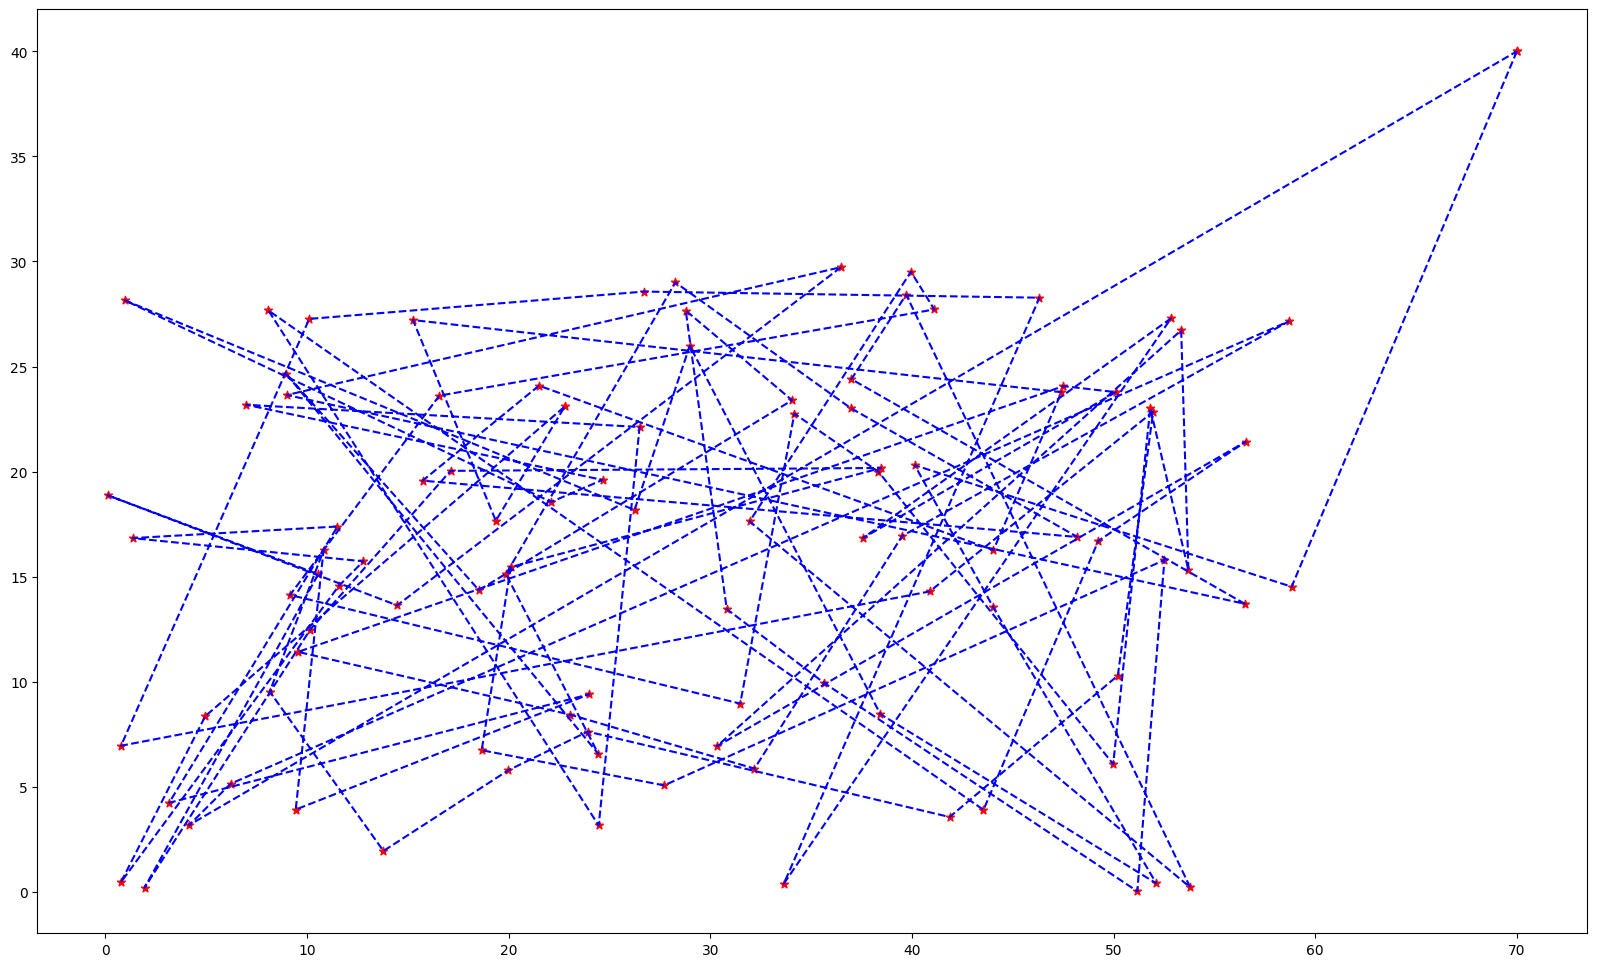

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(0)
w = 50      # 种群规模
g = 100     # 进化代数

J = np.loadtxt('遗传算法初步结果.txt')
J = J / J.shape[1]
print(J.shape)
print(J)

size = J.shape[1]

for k in range(g):
    # ---- 交配 ----
    A = J.copy()                                    # 【修复】必须 copy

    c = np.random.permutation([i for i in range(w)])
    for i in range(0, w, 2):
        F = int(1 + np.floor(100 * np.random.rand()))   # 【修复】标量, 去掉 (1)
        temp = A[c[i], F:].copy()                   # 【修复】.copy() 避免视图
        A[c[i],   F:] = A[c[i+1], F:]
        A[c[i+1], F:] = temp

    # ---- 变异 ----
    by = np.where(np.random.rand(w) < 0.1)[0]       # 【修复】用 np.where
    while len(by) == 0:
        by = np.where(np.random.rand(w) < 0.1)[0]
    B = A[by].copy()

    for j in range(len(by)):
        bw = np.sort(1 + np.floor(100 * np.random.rand(3))).astype(int)   # 【修复】int
        neworder = (list(range(bw[0]))
                    + list(range(bw[1], bw[2]))
                    + list(range(bw[0], bw[1]))
                    + list(range(bw[2], 102)))
        B[j, :] = B[j, neworder]

    # ---- 父代 + 子代 + 变异体 ----
    G = np.concatenate((J, A, B), axis=0)

    # ---- 用 argsort 解码成访问顺序 ----
    SG = np.zeros(G.shape, dtype=int)               # 【修复】int
    for ind in range(G.shape[0]):
        SG[ind] = G[ind].argsort()

    # ---- 计算路径长度 ----
    lengths = np.zeros(G.shape[0], dtype=float)     # 【修复】float
    for ind in range(len(SG)):
        for vex in range(len(SG[ind]) - 1):
            lengths[ind] += d[SG[ind][vex]][SG[ind][vex+1]]

    bestArg = lengths.argsort()
    J = G[bestArg[:50]]                              # 精英保留 50 个

# ---- 输出最优 ----
print("Best length:", lengths[bestArg[0]])
path = SG[bestArg[0]]                                # 【修复】用最优个体
print(path)

plt.figure(figsize=(20, 12))
divide = 1
coordinate_path = np.array([[data[i][0], data[i][1]] for i in path])
plt.scatter(coordinate_path[::divide, 0], coordinate_path[::divide, 1],
            marker='*', color='red')
plt.plot(coordinate_path[::divide, 0], coordinate_path[::divide, 1], 'b--')
plt.show()                                           # 别忘 show

## 5. 小结

初温、降温系数、种群规模与变异率决定搜索效果；随机算法应多次运行并报告统计结果。